# INF201 – Deliverable 1: Weather data from Ås

**Authors:** *Mathias Gundersen, Jakub Mermer*  
**GitHub repository:** *https://github.com/saltonese/Del_1-G6_5.git*

Denne notebooken bruker målinger/data fra Meterologisk Institutt (MET) via
[Frost API](https://frost.met.no) for å finne tempreatur, nedbør og hetebølger 
ved værstasjonen i Ås (`SN17850`)

**Client ID** Frost client IDen er personlig og må derfor ikke havne i GitHub repo-en.
Koden nedenfor leser den fra en fil `Frost_ID` lokalt.

In [1]:

from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yaml

STATION = "SN17850"          # Ås
YEAR = 2025
TEMP_MEAN = "mean(air_temperature P1D)"
TEMP_MAX = "max(air_temperature P1D)"
PRECIP = "sum(precipitation_amount P1D)"

OBS_URL = "https://frost.met.no/observations/v0.jsonld"
SOURCES_URL = "https://frost.met.no/sources/v0.jsonld"


def load_client_id():
    """Read the Frost client ID from a local file."""

    path = Path.cwd().parent / "Frost_ID.txt"  #filen ligger i parent mappen til notebooken
    if path.is_file():
        return path.read_text(encoding="utf-8").strip()

    raise FileNotFoundError(
        f"Could not find Frost_ID.txt in the notebook's working directory: {Path.cwd()}"
    )


CLIENT_ID = load_client_id()

## Hjelpe funksjoner: laste inn data fra Frost

Brukte eksempelkoden fra MET ([frost.met.no/python_example.html](https://frost.met.no/python_example.html))
som utgangspunkt. Måtte endre 2 ting:

* `DataFrame.append` finnes ikke i nåværende versjoner av pandas. tabellen ble laget fra en liste med rows istdet
* Frost kan returnere **felere parallele tids-serier for samme dag** (forkjellig `timeOffset`,
  f.eks. `PT0H` og `PT6H`, som betyr at 24-timers perioden starter på forksjellige tidspunkter). Dersom vi ikke endrer på dette ville hver dag komme opp 2 ganger.
  Funksjonen beholder tidsperioden med flest oberservasjoner og forteller oss når den må velge. 

In [ ]:
def frost_get(url, params):
    """GET from Frost and return the JSON, raising a readable error if it fails."""
    r = requests.get(url, params=params, auth=(CLIENT_ID, ""), timeout=60)
    payload = r.json()
    if r.status_code != 200:
        err = payload.get("error", {})
        raise RuntimeError(
            f"Frost returned {r.status_code}: {err.get('message')} ({err.get('reason')})"
        )
    return payload


def get_daily(station, element, year):
    """Return a pandas Series (index = date) with one daily value per day of `year`."""
    params = {
        "sources": station,
        "elements": element,
        # Går fra 01-01 til 01-01 neste år for å få med alle dagene.
        "referencetime": f"{year}-01-01/{year + 1}-01-01",
    }
    payload = frost_get(OBS_URL, params)

    rows = [
        {"date": item["referenceTime"], "value": obs["value"], "timeOffset": obs.get("timeOffset")}
        for item in payload["data"]
        for obs in item["observations"]
    ]
    df = pd.DataFrame(rows)
    df["date"] = pd.to_datetime(df["date"], utc=True).dt.tz_localize(None).dt.normalize()

    # Several parallel series per day? Keep the one with most observations.
    if df["timeOffset"].nunique() > 1:
        counts = df["timeOffset"].value_counts()
        chosen = counts.idxmax()
        print(f"Note ({element}, {year}): several time offsets {counts.to_dict()}, using {chosen}")
        df = df[df["timeOffset"] == chosen]
    if df["date"].duplicated().any():
        print(f"Warning ({element}, {year}): duplicate dates remain, keeping the first")
        df = df.drop_duplicates("date")

    df = df[df["date"].dt.year == year]
    return df.set_index("date")["value"].sort_index().rename(element)


def resolve_station(station):
    """Accept either a station id ('SN17850') or a station name ('Ås') and return the id."""
    if station.upper().startswith("SN") and station[2:].isdigit():
        return station.upper()
    payload = frost_get(SOURCES_URL, {"name": station})
    matches = {s["id"]: s["name"] for s in payload["data"]}
    exact = [sid for sid, name in matches.items() if name.lower() == station.lower()]
    if len(exact) == 1:
        return exact[0]
    raise ValueError(f"Could not pick a single station for '{station}'. Candidates: {matches}")


def summary_table(series_by_label, unit="°C"):
    """Mean / median / min / max (plus number of days) for one or more series."""
    stats = {
        label: {
            f"Mean ({unit})": f"{s.mean():.1f}",
            f"Median ({unit})": f"{s.median():.1f}",
            f"Min ({unit})": f"{s.min():.1f}",
            f"Max ({unit})": f"{s.max():.1f}",
            "Days with data": f"{s.count()}",
        }
        for label, s in series_by_label.items()
    }
    return pd.DataFrame(stats)

## Task 1: Temperature

In [ ]:
temp = get_daily(STATION, TEMP_MEAN, YEAR)
print(f"Got {len(temp)} days of data")   # Viser hvor mange dager med data
temp.head()

Note (mean(air_temperature P1D), 2025): several time offsets {'PT0H': 365, 'PT6H': 365}, using PT0H
Got 365 days of data


date
2025-01-01    -5.2
2025-01-02   -11.5
2025-01-03    -8.9
2025-01-04   -15.5
2025-01-05   -12.5
Name: mean(air_temperature P1D), dtype: float64

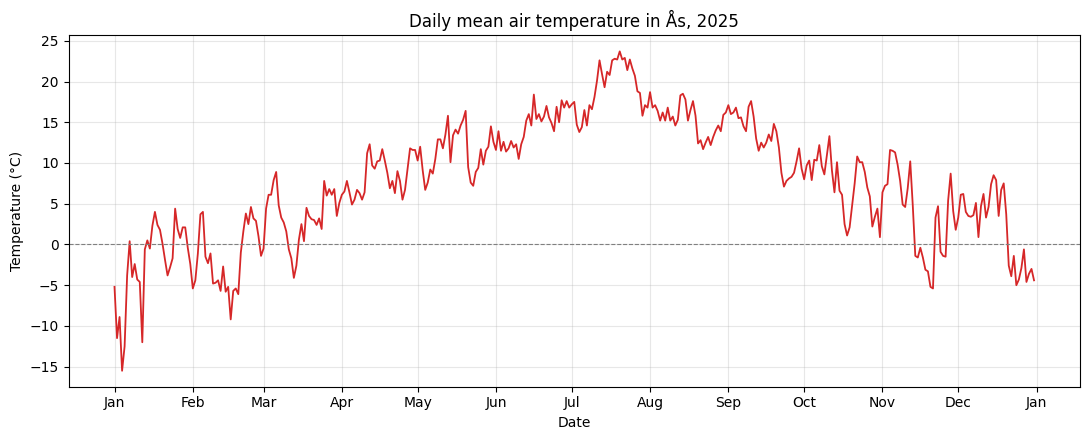

In [4]:
# Plotte datene på tabell
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(temp.index, temp.values, color="tab:red", linewidth=1.3)
ax.set_title(f"Daily mean air temperature in Ås, {YEAR}")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [5]:
#Printer ut oppsumering av tempraturen ila året
print(f"Summary of daily mean temperature, Ås {YEAR}")
print(summary_table({str(YEAR): temp}).to_string())

Summary of daily mean temperature, Ås 2025
                 2025
Mean (°C)         7.9
Median (°C)       8.3
Min (°C)        -15.5
Max (°C)         23.7
Days with data    365
